***The program for calculation of light shifts for two-photon and three-photon Rydberg excitation schemes. Supplemental material for the paper S.A.Spirin et al. Three-dimensional three-photon Stark spectroscopy of single Rydberg Rb atoms in an ultrahigh-vacuum glass cell with eight electrodes***

Omega2/2pi = 1000 MHz ;  D1/2pi = +10 MHz ; D2/2pi = -200 MHz
dressed intermediate states at -605.9 and +415.9 MHz
 R=W3/W1   W1/2pi   W3/2pi  Weff/2pi    T_pi   Pr_max D3_res(num) D3_res(spl)  D3_theory   [MHz, ns]
   0.300    91.29    27.39    2.4802  206.05  0.99394    -1.65054    -1.64877   -1.66088
   0.330    87.01    28.73    2.4802  204.13  0.99529    -1.49533    -1.50097   -1.51037
   0.363    82.94    30.14    2.4802  204.21  0.99631    -1.36369    -1.36661   -1.37377
   0.400    79.05    31.63    2.4802  204.28  0.99684    -1.24414    -1.24452   -1.24983
   0.440    75.35    33.18    2.4802  204.35  0.99699    -1.13544    -1.13362   -1.13740
   0.485    71.82    34.81    2.4802  202.39  0.99755    -1.02621    -1.03293   -1.03544
   0.533    68.46    36.52    2.4802  202.44  0.99834    -0.93659    -0.94156   -0.94303
   0.587    65.25    38.31    2.4802  202.48  0.99887    -0.85541    -0.85870   -0.85930
   0.646    62.19    40.20    2.4802  202.52  0.99919    -0.78187    -0.

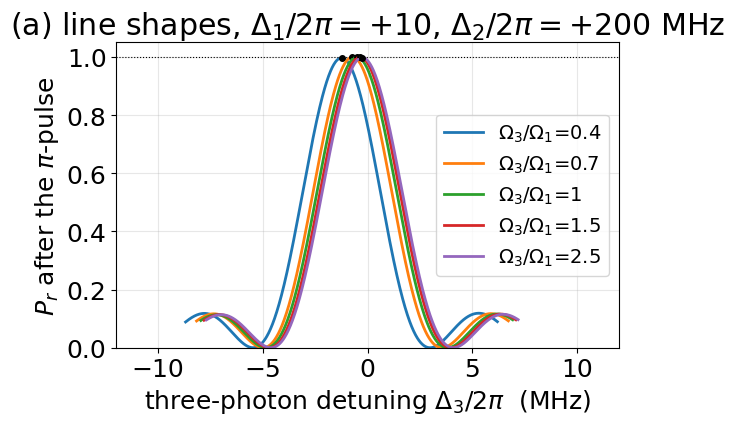

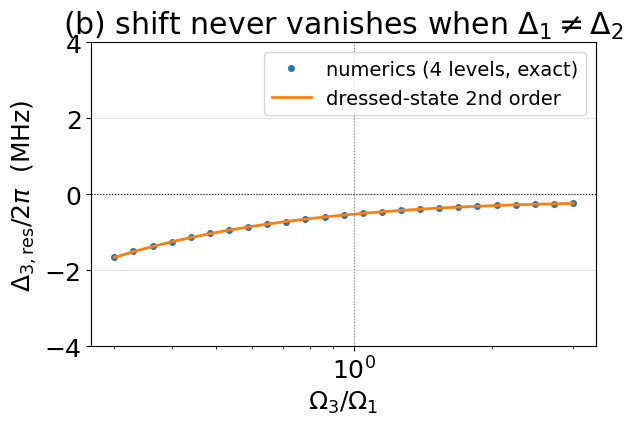

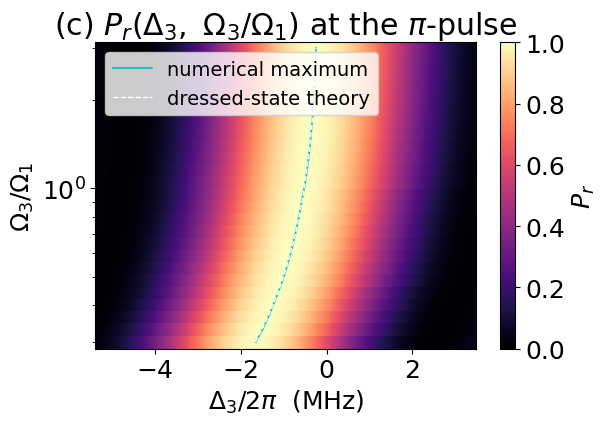

In [22]:
"""
Three-photon Rydberg excitation |g> -> |e1> -> |e2> -> |r>
with FINITE intermediate detunings (ALL DETUNINGS POSITIVE):

    Omega1/2pi = 50 MHz,  Omega2/2pi = 1000 MHz,  Omega3/2pi = 50 MHz
    D1/2pi     = +10 MHz   (one-photon detuning of |e1>)
    D2/2pi     = +200 MHz  (cumulative two-photon detuning of |e2>)

RWA Hamiltonian, basis (g, e1, e2, r), hbar = 1, detunings on the
diagonal with a PLUS sign:

        |  0    W1/2   0     0    |
  H  =  | W1/2  +D1   W2/2   0    |
        |  0    W2/2  +D2   W3/2  |
        |  0     0   W3/2  +D3    |

Scan variable: D3 (three-photon detuning).  Ratio scan: R = Omega3/Omega1 at
fixed product Omega1*Omega3 = W0^2, so R = 1 is the nominal 50/1000/50 point.

NOTE  Omega2/2 = 500 MHz EXCEEDS both detunings, so the usual ladder formulas
      W1*W2*W3/(4*D1*D2) and (W3^2-W1^2)/(4*D) * 1/(1-(W2/2D)^2) are invalid.
      The reference curve here is dressed-state second-order perturbation
      theory: diagonalise the (e1,e2) block, then perturb in W1 and W3.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

MHz = 2.0 * np.pi * 1e6
ns  = 1e-9

# ============================== model ==============================
def H4(W1, W2, W3, D3, D1, D2, gam=0.0):
    """RWA Hamiltonian (g, e1, e2, r); gam = loss of the intermediate states.
       Convention: H_jj = +D_j."""
    H = 0.5 * np.array([[ 0.0,  W1,    0.0,   0.0],
                        [ W1,  +2*D1,   W2,    0.0],
                        [ 0.0,   W2,  +2*D2,   W3 ],
                        [ 0.0,   0.0,   W3,  +2*D3]], dtype=complex)
    if gam:
        H[1, 1] -= 0.5j * gam
        H[2, 2] -= 0.5j * gam
    return H


def mode_coeffs(W1, W2, W3, D3, D1, D2, gam=0.0):
    """<r|psi(t)> = sum_j c_j exp(-i lam_j t) for the initial state |g>."""
    lam, V = np.linalg.eig(H4(W1, W2, W3, D3, D1, D2, gam))
    return lam, V[3, :] * np.linalg.inv(V)[:, 0]


def P_t(ts, lam, c):
    return np.abs(np.exp(-1j * np.outer(np.atleast_1d(ts), lam)) @ c)**2


def P_one(T, W1, W2, W3, D3, D1, D2, gam=0.0):
    lam, c = mode_coeffs(W1, W2, W3, D3, D1, D2, gam)
    return float(P_t(T, lam, c)[0])


def P_many(D3s, W1, W2, W3, T, D1, D2, gam=0.0):
    """P_r over a grid of D3 at fixed T (vectorised eigendecomposition)."""
    D3s = np.atleast_1d(np.asarray(D3s, dtype=float))
    Hs  = np.broadcast_to(H4(W1, W2, W3, 0.0, D1, D2, gam),
                          (D3s.size, 4, 4)).copy()
    Hs[:, 3, 3] = +D3s
    lam, V = np.linalg.eig(Hs)
    c = V[:, 3, :] * np.linalg.inv(V)[:, :, 0]
    return np.abs(np.einsum('nj,nj->n', np.exp(-1j * lam * T), c))**2


def Weff_exact(W1, W2, W3, D3, D1, D2):
    """Exact splitting of the two levels closest to zero."""
    E = np.linalg.eigvalsh(H4(W1, W2, W3, D3, D1, D2))
    E = E[np.argsort(np.abs(E))][:2]
    return abs(E[1] - E[0])


# ============ dressed-state perturbation theory (reference) ============
def dressed(W2, D1, D2):
    """Diagonalise the strongly coupled intermediate block (positive D's).
       Returns dressed energies and (e1,e2) amplitudes (columns)."""
    M = np.array([[+D1, 0.5 * W2], [0.5 * W2, +D2]])
    lam, V = np.linalg.eigh(M)
    return lam, V


def light_shifts(W1, W2, W3, D1, D2):
    """Second-order shifts of |g> (only via e1) and |r> (only via e2)."""
    lam, V = dressed(W2, D1, D2)
    dg = -(W1**2 / 4.0) * np.sum(V[0, :]**2 / lam)
    dr = -(W3**2 / 4.0) * np.sum(V[1, :]**2 / lam)
    return dg, dr


def D3_analytic(W1, W2, W3, D1, D2):
    """Resonance: 0 + dg = D3 + dr  ->  D3_res = dg - dr."""
    dg, dr = light_shifts(W1, W2, W3, D1, D2)
    return dg - dr


def Weff_analytic(W1, W2, W3, D1, D2):
    """Effective splitting = 2 * |sum_s (W1/2)(W3/2) V0s V1s / (-lam_s)|."""
    lam, V = dressed(W2, D1, D2)
    Vgr = (W1 * W3 / 4.0) * np.sum(V[0, :] * V[1, :] / (-lam))
    return 2.0 * abs(Vgr)


# ============================== pi-pulse ==============================
def pulse_time(W1, W2, W3, D1, D2, gam=0.0):
    """Duration maximising P_r at the predicted resonance.
       Grid resolves the fast dressed components (period 2*pi/|lam| ~ 2.5 ns)."""
    Oe = Weff_analytic(W1, W2, W3, D1, D2)
    D3 = D3_analytic(W1, W2, W3, D1, D2)
    lam, c = mode_coeffs(W1, W2, W3, D3, D1, D2, gam)
    fmax = np.abs(lam).max()
    span = 1.5 * np.pi / Oe
    n    = max(6000, int(span * fmax / (2 * np.pi) * 30))
    ts   = np.linspace(0.0, span, n)
    P    = P_t(ts, lam, c)
    i    = int(P.argmax())
    lo, hi = ts[max(i - 1, 0)], ts[min(i + 1, n - 1)]
    r = minimize_scalar(lambda t: -float(P_t(t, lam, c)[0]),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * span})
    return r.x, -r.fun, np.pi / Oe          # T_num, P_r(T_num), T = pi/Omega_eff


def find_resonance(W1, W2, W3, T, D1, D2, gam=0.0, n=801, window=4.0):
    """Peak of P_r(D3) at fixed T, window centred on the dressed-state theory."""
    Oe   = Weff_analytic(W1, W2, W3, D1, D2)
    c0   = D3_analytic(W1, W2, W3, D1, D2)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    P    = P_many(grid, W1, W2, W3, T, D1, D2, gam)
    i    = int(P.argmax())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: -P_one(T, W1, W2, W3, d, D1, D2, gam),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x, -r.fun, grid, P


def find_min_split(W1, W2, W3, D1, D2, n=801, window=4.0):
    """Independent criterion: detuning where the near-zero levels are closest."""
    Oe   = Weff_analytic(W1, W2, W3, D1, D2)
    c0   = D3_analytic(W1, W2, W3, D1, D2)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    S    = np.array([Weff_exact(W1, W2, W3, d, D1, D2) for d in grid])
    i    = int(S.argmin())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: Weff_exact(W1, W2, W3, d, D1, D2),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x


# ============================= parameters =============================
W0  = 50.0 * MHz          # Omega1 * Omega3 = W0^2 ;  R = 1 -> 50/1000/50
W2  = 1000.0 * MHz
D1  = +10.0 * MHz        
D2  = -200.0 * MHz       
gam = 0.0                 # e.g. 2*np.pi*6e6 for intermediate-state decay
ratios = np.logspace(np.log10(0.3), np.log10(3.0), 25)    # R = Omega3/Omega1

W1_of = lambda R: W0 / np.sqrt(R)
W3_of = lambda R: W0 * np.sqrt(R)

lam_d, V_d = dressed(W2, D1, D2)
print(f"Omega2/2pi = {W2/MHz:.0f} MHz ;  D1/2pi = {D1/MHz:+.0f} MHz ; "
      f"D2/2pi = {D2/MHz:+.0f} MHz")
print(f"dressed intermediate states at {lam_d[0]/MHz:+.1f} and "
      f"{lam_d[1]/MHz:+.1f} MHz")


# ================================ sweep ================================
num, splt, pmax, Tnum, Tana, weff_a = [], [], [], [], [], []
for R in ratios:
    T, p, Ta = pulse_time(W1_of(R), W2, W3_of(R), D1, D2, gam)
    Tnum.append(T); pmax.append(p); Tana.append(Ta)
    d, *_ = find_resonance(W1_of(R), W2, W3_of(R), T, D1, D2, gam)
    num.append(d)
    splt.append(find_min_split(W1_of(R), W2, W3_of(R), D1, D2))
    weff_a.append(Weff_analytic(W1_of(R), W2, W3_of(R), D1, D2))
num, splt = np.array(num), np.array(splt)
pmax, Tnum, Tana = np.array(pmax), np.array(Tnum), np.array(Tana)
weff_a = np.array(weff_a)
th = np.array([D3_analytic(W1_of(R), W2, W3_of(R), D1, D2) for R in ratios])

print(f"{'R=W3/W1':>8} {'W1/2pi':>8} {'W3/2pi':>8} {'Weff/2pi':>9} {'T_pi':>7} "
      f"{'Pr_max':>8} {'D3_res(num)':>11} {'D3_res(spl)':>11} {'D3_theory':>10}"
      f"   [MHz, ns]")
for R, p, T, d, s, t, wa in zip(ratios, pmax, Tnum, num, splt, th, weff_a):
    print(f"{R:8.3f} {W1_of(R)/MHz:8.2f} {W3_of(R)/MHz:8.2f} {wa/MHz:9.4f} "
          f"{T/ns:7.2f} {p:8.5f} {d/MHz:11.5f} {s/MHz:11.5f} {t/MHz:10.5f}")

# ================================ plots ================================
show = [0.4, 0.7, 1.0, 1.5, 2.5]
base = "three_photon_D1p10_D2p200_MHz"
plt.rcParams.update({'font.size': 18})
plt.rcParams['lines.linewidth'] = 2
# (a) line shapes
figa, axa = plt.subplots(figsize=(6.4, 4.6))
for R in show:
    T, p, _ = pulse_time(W1_of(R), W2, W3_of(R), D1, D2, gam)
    d, pk, grid, P = find_resonance(W1_of(R), W2, W3_of(R), T, D1, D2, gam,
                                    window=3.0)
    axa.plot(grid / MHz, P, label=rf"$\Omega_3/\Omega_1$={R:g}")
    axa.plot(d / MHz, pk, 'k.', ms=8)
axa.axhline(1.0, color='k', lw=0.8, ls=':')
axa.set_ylim(0, 1.05)
axa.set_xlim(-12, 12)
axa.set_xlabel(r"three-photon detuning $\Delta_3/2\pi$  (MHz)")
axa.set_ylabel(r"$P_r$ after the $\pi$-pulse")
axa.set_title(r"(a) line shapes, $\Delta_1/2\pi=+10$, $\Delta_2/2\pi=+200$ MHz")
axa.legend(fontsize=14)
axa.grid(alpha=0.3)
figa.tight_layout()
figa.savefig(base + "_a_lineshapes.svg")
plt.show()

# (b) resonance position vs ratio
figb, axb = plt.subplots(figsize=(6.4, 4.6))
axb.plot(ratios, num / MHz, 'o', ms=4, label="numerics (4 levels, exact)")
axb.plot(ratios, th / MHz, '-', label="dressed-state 2nd order")
axb.axvline(1, color='gray', lw=0.8, ls=':')
axb.axhline(0, color='k', lw=0.8, ls=':')
axb.set_xscale('log')
axb.set_xlabel(r"$\Omega_3/\Omega_1$")
axb.set_ylabel(r"$\Delta_{3,\rm res}/2\pi$  (MHz)")
axb.set_title(r"(b) shift never vanishes when $\Delta_1\ne\Delta_2$")
axb.set_ylim(-4, 4)
axb.legend(fontsize=14)
axb.grid(alpha=0.3)
figb.tight_layout()
figb.savefig(base + "_b_shift.svg")
plt.show()

# (c) 2D map P_r(D3, ratio)
Oe0   = weff_a[len(ratios) // 2]
dgrid = np.linspace(th.min() - 1.5 * Oe0, th.max() + 1.5 * Oe0, 405)
M = np.array([P_many(dgrid, W1_of(R), W2, W3_of(R), Tnum[i], D1, D2, gam)
              for i, R in enumerate(ratios)])

figc, axc = plt.subplots(figsize=(6.4, 4.6))
im = axc.pcolormesh(dgrid / MHz, ratios, M, shading='auto', cmap='magma',
                    vmin=0, vmax=1)
axc.plot(num / MHz, ratios, 'c-', lw=1.2, label='numerical maximum')
axc.plot(th / MHz, ratios, 'w--', lw=1.0, label='dressed-state theory')
axc.set_yscale('log')
axc.set_xlabel(r"$\Delta_3/2\pi$  (MHz)")
axc.set_ylabel(r"$\Omega_3/\Omega_1$")
axc.set_title(r"(c) $P_r(\Delta_3,\ \Omega_3/\Omega_1)$ at the $\pi$-pulse")
axc.legend(fontsize=14, loc='upper left')
figc.colorbar(im, ax=axc, label=r"$P_r$")
figc.tight_layout()
figc.savefig(base + "_c_map.png", dpi=150)
plt.show()

Omega2/2pi = 1000 MHz ;  D1/2pi = +0 MHz ; D2/2pi = +0 MHz
dressed intermediate states at -500.0 and +500.0 MHz
 R=W3/W1   W1/2pi   W3/2pi  Weff/2pi    T_pi   Pr_max D3_res(num) D3_res(spl)  D3_theory   [MHz, ns]
   0.300    91.29    27.39    2.5000  200.59  0.99593    -0.00000     0.00000    0.00000
   0.330    87.01    28.73    2.5000  200.66  0.99661     0.00000    -0.00000    0.00000
   0.363    82.94    30.14    2.5000  200.72  0.99722     0.00000    -0.00000    0.00000
   0.400    79.05    31.63    2.5000  200.77  0.99776     0.00000    -0.00000    0.00000
   0.440    75.35    33.18    2.5000  200.82  0.99822    -0.00000     0.00000    0.00000
   0.485    71.82    34.81    2.5000  200.86  0.99863     0.00000    -0.00000    0.00000
   0.533    68.46    36.52    2.5000  200.90  0.99898     0.00000     0.00000    0.00000
   0.587    65.25    38.31    2.5000  200.93  0.99927    -0.00000     0.00000    0.00000
   0.646    62.19    40.20    2.5000  200.95  0.99951    -0.00000     0.000

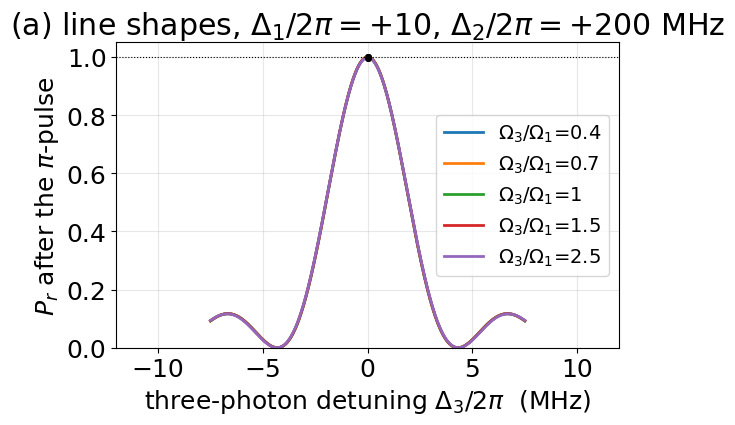

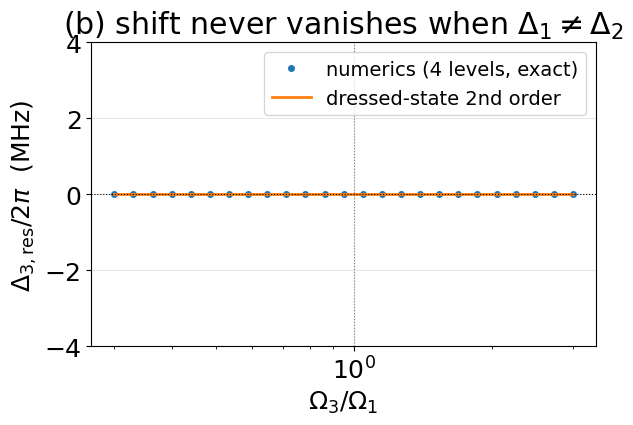

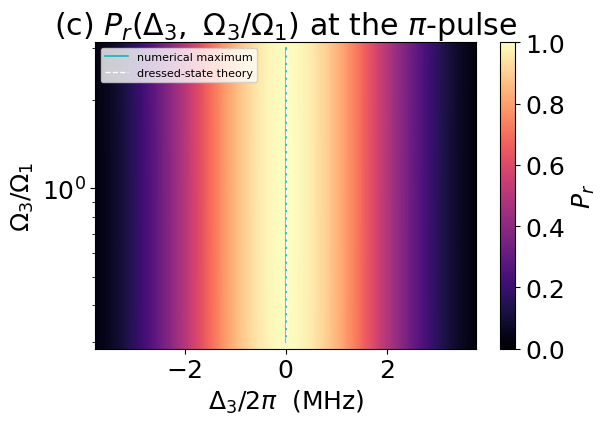

In [20]:
"""
Three-photon Rydberg excitation |g> -> |e1> -> |e2> -> |r>
with FINITE intermediate detunings (ALL DETUNINGS POSITIVE):

    Omega1/2pi = 50 MHz,  Omega2/2pi = 1000 MHz,  Omega3/2pi = 50 MHz
    D1/2pi     = +10 MHz   (one-photon detuning of |e1>)
    D2/2pi     = +200 MHz  (cumulative two-photon detuning of |e2>)

RWA Hamiltonian, basis (g, e1, e2, r), hbar = 1, detunings on the
diagonal with a PLUS sign:

        |  0    W1/2   0     0    |
  H  =  | W1/2  +D1   W2/2   0    |
        |  0    W2/2  +D2   W3/2  |
        |  0     0   W3/2  +D3    |

Scan variable: D3 (three-photon detuning).  Ratio scan: R = Omega3/Omega1 at
fixed product Omega1*Omega3 = W0^2, so R = 1 is the nominal 50/1000/50 point.

NOTE  Omega2/2 = 500 MHz EXCEEDS both detunings, so the usual ladder formulas
      W1*W2*W3/(4*D1*D2) and (W3^2-W1^2)/(4*D) * 1/(1-(W2/2D)^2) are invalid.
      The reference curve here is dressed-state second-order perturbation
      theory: diagonalise the (e1,e2) block, then perturb in W1 and W3.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

MHz = 2.0 * np.pi * 1e6
ns  = 1e-9

# ============================== model ==============================
def H4(W1, W2, W3, D3, D1, D2, gam=0.0):
    """RWA Hamiltonian (g, e1, e2, r); gam = loss of the intermediate states.
       Convention: H_jj = +D_j."""
    H = 0.5 * np.array([[ 0.0,  W1,    0.0,   0.0],
                        [ W1,  +2*D1,   W2,    0.0],
                        [ 0.0,   W2,  +2*D2,   W3 ],
                        [ 0.0,   0.0,   W3,  +2*D3]], dtype=complex)
    if gam:
        H[1, 1] -= 0.5j * gam
        H[2, 2] -= 0.5j * gam
    return H


def mode_coeffs(W1, W2, W3, D3, D1, D2, gam=0.0):
    """<r|psi(t)> = sum_j c_j exp(-i lam_j t) for the initial state |g>."""
    lam, V = np.linalg.eig(H4(W1, W2, W3, D3, D1, D2, gam))
    return lam, V[3, :] * np.linalg.inv(V)[:, 0]


def P_t(ts, lam, c):
    return np.abs(np.exp(-1j * np.outer(np.atleast_1d(ts), lam)) @ c)**2


def P_one(T, W1, W2, W3, D3, D1, D2, gam=0.0):
    lam, c = mode_coeffs(W1, W2, W3, D3, D1, D2, gam)
    return float(P_t(T, lam, c)[0])


def P_many(D3s, W1, W2, W3, T, D1, D2, gam=0.0):
    """P_r over a grid of D3 at fixed T (vectorised eigendecomposition)."""
    D3s = np.atleast_1d(np.asarray(D3s, dtype=float))
    Hs  = np.broadcast_to(H4(W1, W2, W3, 0.0, D1, D2, gam),
                          (D3s.size, 4, 4)).copy()
    Hs[:, 3, 3] = +D3s
    lam, V = np.linalg.eig(Hs)
    c = V[:, 3, :] * np.linalg.inv(V)[:, :, 0]
    return np.abs(np.einsum('nj,nj->n', np.exp(-1j * lam * T), c))**2


def Weff_exact(W1, W2, W3, D3, D1, D2):
    """Exact splitting of the two levels closest to zero."""
    E = np.linalg.eigvalsh(H4(W1, W2, W3, D3, D1, D2))
    E = E[np.argsort(np.abs(E))][:2]
    return abs(E[1] - E[0])


# ============ dressed-state perturbation theory (reference) ============
def dressed(W2, D1, D2):
    """Diagonalise the strongly coupled intermediate block (positive D's).
       Returns dressed energies and (e1,e2) amplitudes (columns)."""
    M = np.array([[+D1, 0.5 * W2], [0.5 * W2, +D2]])
    lam, V = np.linalg.eigh(M)
    return lam, V


def light_shifts(W1, W2, W3, D1, D2):
    """Second-order shifts of |g> (only via e1) and |r> (only via e2)."""
    lam, V = dressed(W2, D1, D2)
    dg = -(W1**2 / 4.0) * np.sum(V[0, :]**2 / lam)
    dr = -(W3**2 / 4.0) * np.sum(V[1, :]**2 / lam)
    return dg, dr


def D3_analytic(W1, W2, W3, D1, D2):
    """Resonance: 0 + dg = D3 + dr  ->  D3_res = dg - dr."""
    dg, dr = light_shifts(W1, W2, W3, D1, D2)
    return dg - dr


def Weff_analytic(W1, W2, W3, D1, D2):
    """Effective splitting = 2 * |sum_s (W1/2)(W3/2) V0s V1s / (-lam_s)|."""
    lam, V = dressed(W2, D1, D2)
    Vgr = (W1 * W3 / 4.0) * np.sum(V[0, :] * V[1, :] / (-lam))
    return 2.0 * abs(Vgr)


# ============================== pi-pulse ==============================
def pulse_time(W1, W2, W3, D1, D2, gam=0.0):
    """Duration maximising P_r at the predicted resonance.
       Grid resolves the fast dressed components (period 2*pi/|lam| ~ 2.5 ns)."""
    Oe = Weff_analytic(W1, W2, W3, D1, D2)
    D3 = D3_analytic(W1, W2, W3, D1, D2)
    lam, c = mode_coeffs(W1, W2, W3, D3, D1, D2, gam)
    fmax = np.abs(lam).max()
    span = 1.5 * np.pi / Oe
    n    = max(6000, int(span * fmax / (2 * np.pi) * 30))
    ts   = np.linspace(0.0, span, n)
    P    = P_t(ts, lam, c)
    i    = int(P.argmax())
    lo, hi = ts[max(i - 1, 0)], ts[min(i + 1, n - 1)]
    r = minimize_scalar(lambda t: -float(P_t(t, lam, c)[0]),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * span})
    return r.x, -r.fun, np.pi / Oe          # T_num, P_r(T_num), T = pi/Omega_eff


def find_resonance(W1, W2, W3, T, D1, D2, gam=0.0, n=801, window=4.0):
    """Peak of P_r(D3) at fixed T, window centred on the dressed-state theory."""
    Oe   = Weff_analytic(W1, W2, W3, D1, D2)
    c0   = D3_analytic(W1, W2, W3, D1, D2)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    P    = P_many(grid, W1, W2, W3, T, D1, D2, gam)
    i    = int(P.argmax())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: -P_one(T, W1, W2, W3, d, D1, D2, gam),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x, -r.fun, grid, P


def find_min_split(W1, W2, W3, D1, D2, n=801, window=4.0):
    """Independent criterion: detuning where the near-zero levels are closest."""
    Oe   = Weff_analytic(W1, W2, W3, D1, D2)
    c0   = D3_analytic(W1, W2, W3, D1, D2)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    S    = np.array([Weff_exact(W1, W2, W3, d, D1, D2) for d in grid])
    i    = int(S.argmin())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: Weff_exact(W1, W2, W3, d, D1, D2),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x


# ============================= parameters =============================
W0  = 50.0 * MHz          # Omega1 * Omega3 = W0^2 ;  R = 1 -> 50/1000/50
W2  = 1000.0 * MHz
D1  = 0.0 * MHz         # positive
D2  = 0.0 * MHz        # positive
gam = 0.0                 # e.g. 2*np.pi*6e6 for intermediate-state decay
ratios = np.logspace(np.log10(0.3), np.log10(3.0), 25)    # R = Omega3/Omega1

W1_of = lambda R: W0 / np.sqrt(R)
W3_of = lambda R: W0 * np.sqrt(R)

lam_d, V_d = dressed(W2, D1, D2)
print(f"Omega2/2pi = {W2/MHz:.0f} MHz ;  D1/2pi = {D1/MHz:+.0f} MHz ; "
      f"D2/2pi = {D2/MHz:+.0f} MHz")
print(f"dressed intermediate states at {lam_d[0]/MHz:+.1f} and "
      f"{lam_d[1]/MHz:+.1f} MHz")


# ================================ sweep ================================
num, splt, pmax, Tnum, Tana, weff_a = [], [], [], [], [], []
for R in ratios:
    T, p, Ta = pulse_time(W1_of(R), W2, W3_of(R), D1, D2, gam)
    Tnum.append(T); pmax.append(p); Tana.append(Ta)
    d, *_ = find_resonance(W1_of(R), W2, W3_of(R), T, D1, D2, gam)
    num.append(d)
    splt.append(find_min_split(W1_of(R), W2, W3_of(R), D1, D2))
    weff_a.append(Weff_analytic(W1_of(R), W2, W3_of(R), D1, D2))
num, splt = np.array(num), np.array(splt)
pmax, Tnum, Tana = np.array(pmax), np.array(Tnum), np.array(Tana)
weff_a = np.array(weff_a)
th = np.array([D3_analytic(W1_of(R), W2, W3_of(R), D1, D2) for R in ratios])

print(f"{'R=W3/W1':>8} {'W1/2pi':>8} {'W3/2pi':>8} {'Weff/2pi':>9} {'T_pi':>7} "
      f"{'Pr_max':>8} {'D3_res(num)':>11} {'D3_res(spl)':>11} {'D3_theory':>10}"
      f"   [MHz, ns]")
for R, p, T, d, s, t, wa in zip(ratios, pmax, Tnum, num, splt, th, weff_a):
    print(f"{R:8.3f} {W1_of(R)/MHz:8.2f} {W3_of(R)/MHz:8.2f} {wa/MHz:9.4f} "
          f"{T/ns:7.2f} {p:8.5f} {d/MHz:11.5f} {s/MHz:11.5f} {t/MHz:10.5f}")

# ================================ plots ================================
show = [0.4, 0.7, 1.0, 1.5, 2.5]
base = "three_photon_D1p10_D2p200_MHz"
plt.rcParams.update({'font.size': 18})
plt.rcParams['lines.linewidth'] = 2
# (a) line shapes
figa, axa = plt.subplots(figsize=(6.4, 4.6))
for R in show:
    T, p, _ = pulse_time(W1_of(R), W2, W3_of(R), D1, D2, gam)
    d, pk, grid, P = find_resonance(W1_of(R), W2, W3_of(R), T, D1, D2, gam,
                                    window=3.0)
    axa.plot(grid / MHz, P, label=rf"$\Omega_3/\Omega_1$={R:g}")
    axa.plot(d / MHz, pk, 'k.', ms=8)
axa.axhline(1.0, color='k', lw=0.8, ls=':')
axa.set_ylim(0, 1.05)
axa.set_xlim(-12, 12)
axa.set_xlabel(r"three-photon detuning $\Delta_3/2\pi$  (MHz)")
axa.set_ylabel(r"$P_r$ after the $\pi$-pulse")
axa.set_title(r"(a) line shapes, $\Delta_1/2\pi=+10$, $\Delta_2/2\pi=+200$ MHz")
axa.legend(fontsize=14)
axa.grid(alpha=0.3)
figa.tight_layout()
figa.savefig(base + "_a_lineshapes.svg", dpi=150)
plt.show()

# (b) resonance position vs ratio
figb, axb = plt.subplots(figsize=(6.4, 4.6))
axb.plot(ratios, num / MHz, 'o', ms=4, label="numerics (4 levels, exact)")
axb.plot(ratios, th / MHz, '-', label="dressed-state 2nd order")
axb.axvline(1, color='gray', lw=0.8, ls=':')
axb.axhline(0, color='k', lw=0.8, ls=':')
axb.set_xscale('log')
axb.set_xlabel(r"$\Omega_3/\Omega_1$")
axb.set_ylabel(r"$\Delta_{3,\rm res}/2\pi$  (MHz)")
axb.set_title(r"(b) shift never vanishes when $\Delta_1\ne\Delta_2$")
axb.set_ylim(-4, 4)
axb.legend(fontsize=14)
axb.grid(alpha=0.3)
figb.tight_layout()
figb.savefig(base + "_b_shift.svg", dpi=150)
plt.show()

# (c) 2D map P_r(D3, ratio)
Oe0   = weff_a[len(ratios) // 2]
dgrid = np.linspace(th.min() - 1.5 * Oe0, th.max() + 1.5 * Oe0, 405)
M = np.array([P_many(dgrid, W1_of(R), W2, W3_of(R), Tnum[i], D1, D2, gam)
              for i, R in enumerate(ratios)])

figc, axc = plt.subplots(figsize=(6.4, 4.6))
im = axc.pcolormesh(dgrid / MHz, ratios, M, shading='auto', cmap='magma',
                    vmin=0, vmax=1)
axc.plot(num / MHz, ratios, 'c-', lw=1.2, label='numerical maximum')
axc.plot(th / MHz, ratios, 'w--', lw=1.0, label='dressed-state theory')
axc.set_yscale('log')
axc.set_xlabel(r"$\Delta_3/2\pi$  (MHz)")
axc.set_ylabel(r"$\Omega_3/\Omega_1$")
axc.set_title(r"(c) $P_r(\Delta_3,\ \Omega_3/\Omega_1)$ at the $\pi$-pulse")
axc.legend(fontsize=8, loc='upper left')
figc.colorbar(im, ax=axc, label=r"$P_r$")
figc.tight_layout()
figc.savefig(base + "_c_map.png", dpi=150)
plt.show()

Omega1*Omega2 = (50.0 MHz)^2 ;  Delta/2pi = 500.0 MHz ; Omega_eff/2pi = 2.500 MHz ; T_pi = 200.0 ns

 R=W2/W1      W1      W2     Weff    T_pi   Pr_max  dd_res(num)  dd_res(spl)   leading   refined   [MHz, ns]
   0.300   91.29   27.39   2.5000  202.01  0.99579      -3.7607      -3.7666   -3.7917   -3.7945
   0.330   87.01   28.73   2.5000  202.29  0.99653      -3.3477      -3.3536   -3.3727   -3.3755
   0.363   82.94   30.14   2.5000  202.55  0.99716      -2.9648      -2.9707   -2.9849   -2.9876
   0.400   79.05   31.63   2.5000  202.78  0.99768      -2.6085      -2.6144   -2.6245   -2.6271
   0.440   75.35   33.18   2.5000  201.01  0.99816      -2.2754      -2.2815   -2.2883   -2.2908
   0.485   71.82   34.81   2.5000  201.19  0.99860      -1.9631      -1.9692   -1.9732   -1.9756
   0.533   68.46   36.52   2.5000  201.36  0.99897      -1.6685      -1.6746   -1.6762   -1.6785
   0.587   65.25   38.31   2.5000  201.50  0.99927      -1.3889      -1.3950   -1.3947   -1.3968
   0.646   62.

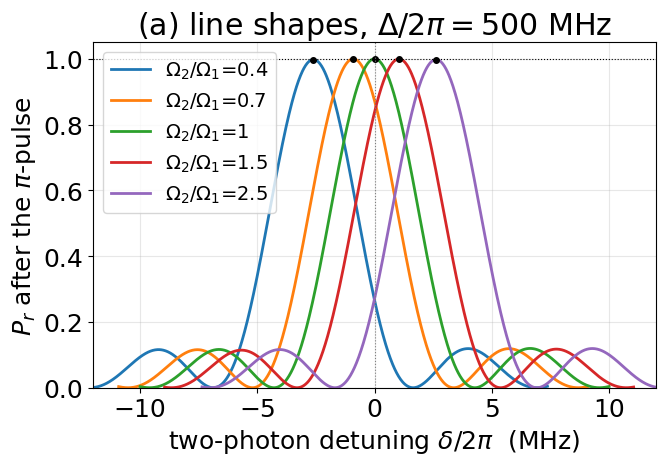

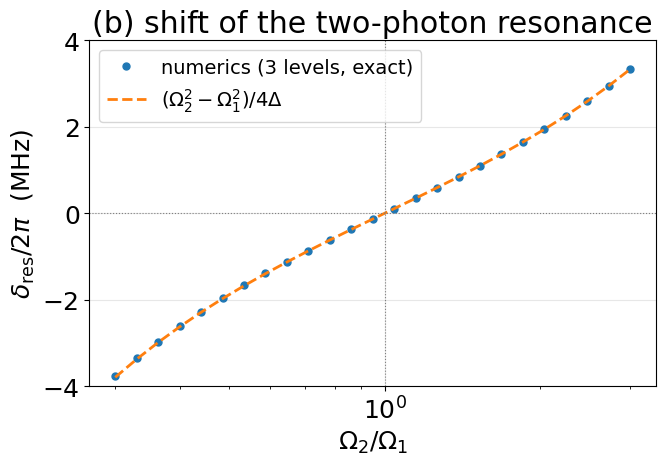

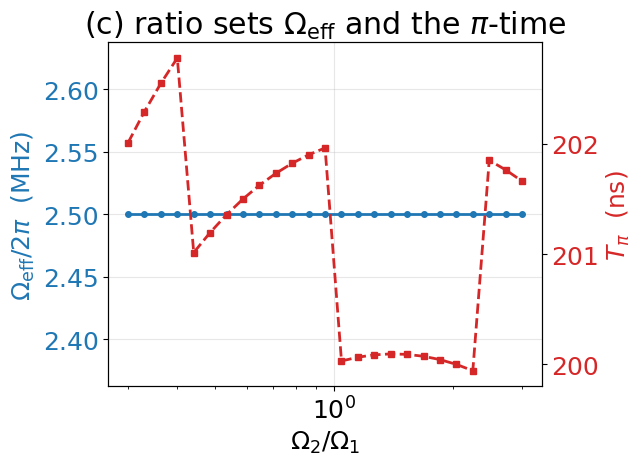

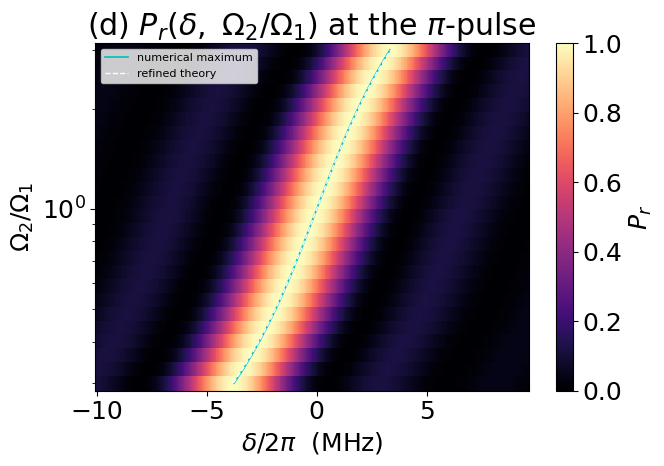

In [18]:
"""
Two-photon Rydberg excitation |g> -> |e> -> |r>, large intermediate detuning.
All frequencies in MHz, times in ns.

    Omega1 = W0/sqrt(R),  Omega2 = W0*sqrt(R),  R = Omega2/Omega1
    product Omega1*Omega2 = W0^2 fixed -> Omega_eff the same for every R

RWA Hamiltonian, basis (g, e, r), hbar = 1, POSITIVE-DETUNING convention:

        |  0    W1/2    0   |
  H  =  | W1/2    D    W2/2 |
        |  0    W2/2    dd  |

D  : one-photon detuning of |e>          (fixed, D > 0 = blue of |e>)
dd : two-photon detuning                 (scan variable)

Second-order (dispersive) energies, D >> W1, W2, |dd|:

    E_g = -W1^2 / (4 D)                      (denominator 0 - D)
    E_r =  dd - W2^2 / (4 (D - dd))          (denominator dd - D)

Reference curves (E_g = E_r):
  leading  : dd_res = dg - dr = (W2^2 - W1^2) / (4 D)
  refined  : small root of  4D*dd^2 + (W1^2 - 4D^2)*dd + D*(W2^2 - W1^2) = 0
             (keeps dd in the energy denominator)
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

MHz = 2.0 * np.pi * 1e6
ns  = 1e-9

# ============================== model ==============================
def H3(W1, W2, D, dd, gam=0.0):
    """RWA Hamiltonian (g, e, r); gam = decay of the intermediate state.

    Positive-detuning convention: diag(0, D, dd).
    """
    H = 0.5 * np.array([[ 0.0,  W1,   0.0  ],
                        [ W1,  2*D,   W2   ],
                        [ 0.0,  W2,  2*dd  ]], dtype=complex)
    if gam:
        H[1, 1] -= 0.5j * gam
    return H


def mode_coeffs(W1, W2, D, dd, gam=0.0):
    """<r|psi(t)> = sum_j c_j exp(-i lam_j t) for the initial state |g>."""
    lam, V = np.linalg.eig(H3(W1, W2, D, dd, gam))
    return lam, V[2, :] * np.linalg.inv(V)[:, 0]


def P_t(ts, lam, c):
    return np.abs(np.exp(-1j * np.outer(np.atleast_1d(ts), lam)) @ c)**2


def P_one(T, W1, W2, D, dd, gam=0.0):
    lam, c = mode_coeffs(W1, W2, D, dd, gam)
    return float(P_t(T, lam, c)[0])


def P_many(dds, W1, W2, D, T, gam=0.0):
    """P_r over a grid of dd at fixed T (vectorised eigendecomposition).

    H[2,2] = +dd, consistent with H3 (this was the sign bug).
    """
    dds = np.atleast_1d(np.asarray(dds, dtype=float))
    Hs  = np.broadcast_to(H3(W1, W2, D, 0.0, gam), (dds.size, 3, 3)).copy()
    Hs[:, 2, 2] = dds                      # <-- +dd, not -dd
    lam, V = np.linalg.eig(Hs)
    c = V[:, 2, :] * np.linalg.inv(V)[:, :, 0]
    return np.abs(np.einsum('nj,nj->n', np.exp(-1j * lam * T), c))**2


def Weff_exact(W1, W2, D, dd=0.0):
    """Exact splitting of the two levels closest to zero, in MHz."""
    E = np.linalg.eigvalsh(H3(W1, W2, D, dd))
    E = E[np.argsort(np.abs(E))][:2]
    return abs(E[1] - E[0])


# ==================== closed-form reference ====================
def light_shifts(W1, W2, D):
    """Leading light shifts of |g> and |r> for diag(0, D, dd), in MHz."""
    return -W1**2 / (4.0 * D), -W2**2 / (4.0 * D)


def Weff_analytic(W1, W2, D):
    return abs(W1 * W2 / (2.0 * D))


def dd_res_leading(W1, W2, D):
    """dd_res = dg - dr = (W2^2 - W1^2) / (4 D)."""
    dg, dr = light_shifts(W1, W2, D)
    return dg - dr


def dd_res_refined(W1, W2, D):
    """Small root of 4D*dd^2 + (W1^2 - 4D^2)*dd + D*(W2^2 - W1^2) = 0."""
    A, B, C = 4.0 * D, W1**2 - 4.0 * D**2, D * (W2**2 - W1**2)
    d0   = dd_res_leading(W1, W2, D)
    disc = np.sqrt(max(B * B - 4.0 * A * C, 0.0))
    r1, r2 = (-B + disc) / (2.0 * A), (-B - disc) / (2.0 * A)
    return r1 if abs(r1 - d0) < abs(r2 - d0) else r2


# ============================== pi-pulse ==============================
def pulse_time(W1, W2, D, gam=0.0):
    """Duration maximising P_r at the predicted resonance."""
    Oe = Weff_analytic(W1, W2, D)
    d0 = dd_res_refined(W1, W2, D)
    lam, c = mode_coeffs(W1, W2, D, d0, gam)
    fmax = np.abs(lam).max()
    span = 1.5 * np.pi / Oe
    n    = max(6000, int(span * fmax / (2.0 * np.pi) * 30))
    ts   = np.linspace(0.0, span, n)
    P    = P_t(ts, lam, c)
    i    = int(P.argmax())
    lo, hi = ts[max(i - 1, 0)], ts[min(i + 1, n - 1)]
    r = minimize_scalar(lambda t: -float(P_t(t, lam, c)[0]),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * span})
    return r.x, -r.fun, np.pi / Oe          # T_num, P_r(T_num), T = pi/Omega_eff


def find_resonance(W1, W2, D, T, gam=0.0, n=1201, window=4.0):
    """Peak of P_r(dd) at fixed T, window centred on the closed form."""
    Oe   = Weff_analytic(W1, W2, D)
    c0   = dd_res_refined(W1, W2, D)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    P    = P_many(grid, W1, W2, D, T, gam)
    i    = int(P.argmax())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: -P_one(T, W1, W2, D, d, gam),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x, -r.fun, grid, P


def find_min_split(W1, W2, D, n=1201, window=4.0):
    """Independent criterion: dd where the near-zero levels are closest."""
    Oe   = Weff_analytic(W1, W2, D)
    c0   = dd_res_refined(W1, W2, D)
    grid = c0 + np.linspace(-window * Oe, window * Oe, n)
    S    = np.array([Weff_exact(W1, W2, D, d) for d in grid])
    i    = int(S.argmin())
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, n - 1)]
    r = minimize_scalar(lambda d: Weff_exact(W1, W2, D, d),
                        bounds=(lo, hi), method='bounded',
                        options={'xatol': 1e-9 * Oe})
    return r.x


# ============================= parameters =============================
W0  = 50.0 * MHz          # Omega1 * Omega2 = W0^2 ; R = 1 -> 50/50 MHz
D   = 500.0 * MHz         # one-photon detuning of |e>  (positive)
gam = 0.0                 # e.g. 2*np.pi*6e6 for intermediate-state decay
ratios = np.logspace(np.log10(0.3), np.log10(3.0), 25)   # R = Omega2/Omega1

W1_of = lambda R: W0 / np.sqrt(R)
W2_of = lambda R: W0 * np.sqrt(R)

print(f"Omega1*Omega2 = ({W0/MHz:.1f} MHz)^2 ;  Delta/2pi = {D/MHz:.1f} MHz ; "
      f"Omega_eff/2pi = {Weff_analytic(W0, W0, D)/MHz:.3f} MHz ; "
      f"T_pi = {np.pi/Weff_analytic(W0, W0, D)/ns:.1f} ns\n")

# -------- sanity check: H3 and P_many must agree on the sign of dd --------
_dtest = 1.3 * MHz
_Ttest = np.pi / Weff_analytic(W0, W0, D)
assert abs(P_one(_Ttest, W0, 2*W0, D, _dtest)
           - P_many(_dtest, W0, 2*W0, D, _Ttest)[0]) < 1e-12, \
       "H3 and P_many use different sign conventions for dd"

# ================================ sweep ================================
num, splt, pmax, Tnum, weff = [], [], [], [], []
for R in ratios:
    T, p, _ = pulse_time(W1_of(R), W2_of(R), D, gam)
    Tnum.append(T); pmax.append(p)
    d, *_ = find_resonance(W1_of(R), W2_of(R), D, T, gam)
    num.append(d)
    splt.append(find_min_split(W1_of(R), W2_of(R), D))
    weff.append(Weff_analytic(W1_of(R), W2_of(R), D))
num, splt = np.array(num), np.array(splt)
pmax, Tnum, weff = np.array(pmax), np.array(Tnum), np.array(weff)
th0 = np.array([dd_res_leading(W1_of(R), W2_of(R), D) for R in ratios])
th1 = np.array([dd_res_refined(W1_of(R), W2_of(R), D) for R in ratios])

print(f"{'R=W2/W1':>8} {'W1':>7} {'W2':>7} {'Weff':>8} {'T_pi':>7} {'Pr_max':>8} "
      f"{'dd_res(num)':>12} {'dd_res(spl)':>12} {'leading':>9} {'refined':>9}"
      f"   [MHz, ns]")
for R, p, T, d, s, a, b in zip(ratios, pmax, Tnum, num, splt, th0, th1):
    print(f"{R:8.3f} {W1_of(R)/MHz:7.2f} {W2_of(R)/MHz:7.2f} "
          f"{Weff_analytic(W1_of(R), W2_of(R), D)/MHz:8.4f} {T/ns:7.2f} "
          f"{p:8.5f} {d/MHz:12.4f} {s/MHz:12.4f} {a/MHz:9.4f} {b/MHz:9.4f}")

print(f"\nmax |numerics - refined| = {np.abs(num - th1).max()/MHz:.4f} MHz ; "
      f"max |numerics - min-splitting| = {np.abs(num - splt).max()/MHz:.4f} MHz")

# ================================ plots ================================

show = [0.4, 0.7, 1.0, 1.5, 2.5]
plt.rcParams.update({'font.size': 18})
plt.rcParams['lines.linewidth'] = 2
def save(fig, name):
    fig.tight_layout()
    fig.savefig(name, dpi=150)
    print("saved", name)

# (a) line shapes, dd axis in MHz
fig, ax = plt.subplots(figsize=(7, 5))
for R in show:
    T, p, _ = pulse_time(W1_of(R), W2_of(R), D, gam)
    d, pk, grid, P = find_resonance(W1_of(R), W2_of(R), D, T, gam)
    ax.plot(grid / MHz, P, label=rf"$\Omega_2/\Omega_1$={R:g}")
    ax.plot(d / MHz, pk, 'k.', ms=8)
ax.axhline(1.0, color='k', lw=0.8, ls=':')
ax.axvline(0.0, color='gray', lw=0.8, ls=':')
ax.set_ylim(0, 1.05)
ax.set_xlim(-12, 12)
ax.set_xlabel(r"two-photon detuning $\delta/2\pi$  (MHz)")
ax.set_ylabel(r"$P_r$ after the $\pi$-pulse")
ax.set_title(rf"(a) line shapes, $\Delta/2\pi={D/MHz:.0f}$ MHz")
ax.legend(fontsize=14); ax.grid(alpha=0.3)
save(fig, "a_line_shapes_MHz.svg")

# (b) shift vs ratio, in MHz
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(ratios, num / MHz, 'o', ms=5, label="numerics (3 levels, exact)")
ax.plot(ratios, th0 / MHz, '--', label=r"$(\Omega_2^2-\Omega_1^2)/4\Delta$")
ax.axhline(0.0, color='gray', lw=0.8, ls=':')
ax.axvline(1.0, color='gray', lw=0.8, ls=':')
ax.set_xscale('log')
ax.set_ylim(-4, 4)
ax.set_xlabel(r"$\Omega_2/\Omega_1$")
ax.set_ylabel(r"$\delta_{\rm res}/2\pi$  (MHz)")
ax.set_title(r"(b) shift of the two-photon resonance")
ax.legend(fontsize=14); ax.grid(alpha=0.3)
save(fig, "b_shift_vs_ratio_MHz.svg")

# (c) Omega_eff and pi-time vs ratio
fig, axc = plt.subplots(figsize=(7, 5))
axc.plot(ratios, weff / MHz, 'o-', ms=4, color='tab:blue',
         label=r"$\Omega_{\rm eff}/2\pi$")
axc.set_xscale('log')
axc.set_xlabel(r"$\Omega_2/\Omega_1$")
axc.set_ylabel(r"$\Omega_{\rm eff}/2\pi$  (MHz)", color='tab:blue')
axc.tick_params(axis='y', labelcolor='tab:blue')
axt = axc.twinx()
axt.plot(ratios, Tnum / ns, 's--', ms=4, color='tab:red', label=r"$T_\pi$")
axt.set_ylabel(r"$T_\pi$  (ns)", color='tab:red')
axt.tick_params(axis='y', labelcolor='tab:red')
axc.set_title(r"(c) ratio sets $\Omega_{\rm eff}$ and the $\pi$-time")
axc.grid(alpha=0.3)
save(fig, "c_omeff_pitime_MHz.svg")

# (d) 2D map P_r(dd, ratio)
fig, ax = plt.subplots(figsize=(7, 5))
dgrid = np.linspace((th1.min() - 2.5 * weff.max()),
                    (th1.max() + 2.5 * weff.max()), 501)
M = np.array([P_many(dgrid, W1_of(R), W2_of(R), D, Tnum[i], gam)
              for i, R in enumerate(ratios)])
im = ax.pcolormesh(dgrid / MHz, ratios, M, shading='auto', cmap='magma',
                   vmin=0, vmax=1)
ax.plot(num / MHz, ratios, 'c-', lw=1.2, label='numerical maximum')
ax.plot(th1 / MHz, ratios, 'w--', lw=1.0, label='refined theory')
ax.set_yscale('log')
ax.set_xlabel(r"$\delta/2\pi$  (MHz)")
ax.set_ylabel(r"$\Omega_2/\Omega_1$")
ax.set_title(r"(d) $P_r(\delta,\ \Omega_2/\Omega_1)$ at the $\pi$-pulse")
ax.legend(fontsize=8, loc='upper left')
fig.colorbar(im, ax=ax, label=r"$P_r$")
save(fig, "d_map_Pr_MHz.png")

plt.show()
